In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

In [5]:
connection_url = URL.create(
    "mssql+pyodbc",
    host=r"(local)\SQLEXPRESS",
    database="Banking EDA",
    query={
        "driver": "ODBC Driver 17 for SQL Server",
        "trusted_connection": "yes"
    }
)

engine = create_engine(connection_url)

try:
    with engine.connect() as conn:
        print("Connected successfully!")
except Exception as e:
    print(e)

Connected successfully!


In [9]:
df = pd.read_sql(
    "SELECT * FROM customers",  #dbo.db_customer
    engine
)

df.head()

,Client_ID,Name,Age,Location_ID,Joined_Bank,Banking_Contact,Nationality,Occupation,Fee_Structure,Loyalty_Classification,...,Bank_Deposits,Checking_Accounts,Saving_Accounts,Foreign_Currency_Account,Business_Lending,Properties_Owned,Risk_Weighting,BRId,GenderId,IAId
0,IND81288,Raymond Mills,24,34324,2019-06-05,Anthony Torres,American,Safety Technician IV,High,Jade,...,1.485829e+06,6.036179e+05,607332.437500,12249.959961,1.134475e+06,1,2,1,1,1
1,IND65833,Julia Spencer,23,42205,2001-10-12,Jonathan Hawkins,African,Software Consultant,High,Jade,...,6.414828e+05,2.295214e+05,344635.156250,61162.308594,2.000526e+06,1,3,2,1,2
2,IND47499,Stephen Murray,27,7314,2010-01-25,Anthony Berry,European,Help Desk Operator,High,Gold,...,1.033402e+06,6.526747e+05,203054.343750,79071.781250,5.481376e+05,1,3,3,2,3
3,IND72498,Virginia Garza,40,34594,2019-03-28,Steve Diaz,American,Geologist II,Mid,Silver,...,1.048158e+06,1.048158e+06,234685.015625,57513.648438,1.148402e+06,0,4,4,1,4
4,IND60181,Melissa Sanders,46,41269,2012-07-20,Shawn Long,American,Assistant Professor,Mid,Platinum,...,4.877825e+05,4.466442e+05,128351.453125,30012.140625,1.674412e+06,0,3,1,2,5


In [20]:
df.shape  #(3000, 25)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Client_ID                 3000 non-null   object 
 1   Name                      3000 non-null   object 
 2   Age                       3000 non-null   int64  
 3   Location_ID               3000 non-null   int64  
 4   Joined_Bank               3000 non-null   object 
 5   Banking_Contact           3000 non-null   object 
 6   Nationality               3000 non-null   object 
 7   Occupation                3000 non-null   object 
 8   Fee_Structure             3000 non-null   object 
 9   Loyalty_Classification    3000 non-null   object 
 10  Estimated_Income          3000 non-null   float64
 11  Superannuation_Savings    3000 non-null   float64
 12  Amount_of_Credit_Cards    3000 non-null   int64  
 13  Credit_Card_Balance       3000 non-null   float64
 14  Bank_Loa

In [21]:
#Generating Descriptive for Dataframe
df.describe() 

,Age,Location_ID,Estimated_Income,Superannuation_Savings,Amount_of_Credit_Cards,Credit_Card_Balance,Bank_Loans,Bank_Deposits,Checking_Accounts,Saving_Accounts,Foreign_Currency_Account,Business_Lending,Properties_Owned,Risk_Weighting,BRId,GenderId,IAId
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3.000000e+03,3.000000e+03,3.000000e+03,3.000000e+03,3000.000000,3.000000e+03,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,51.039667,21563.323000,171305.034184,25531.599685,1.463667,3176.206944,5.913862e+05,6.715602e+05,3.210929e+05,2.329084e+05,29883.529998,8.667598e+05,1.518667,2.249333,2.559333,1.504000,10.425333
std,19.854760,12462.273017,111935.808180,16259.950768,0.676387,2497.094709,4.575570e+05,6.457169e+05,2.820796e+05,2.300078e+05,23109.924033,6.412303e+05,1.102145,1.131191,1.007713,0.500067,5.988242
min,17.000000,12.000000,15919.480469,1482.030029,1.000000,1.170000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,45.000000,0.000000e+00,0.000000,1.000000,1.000000,1.000000,1.000000
25%,34.000000,10803.500000,82906.597656,12513.774902,1.000000,1236.630005,2.396281e+05,2.044004e+05,1.199475e+05,7.479440e+04,11916.542236,3.748251e+05,1.000000,1.000000,2.000000,1.000000,5.000000
50%,51.000000,21129.500000,142313.476562,22357.355469,1.000000,2560.804932,4.797934e+05,4.633165e+05,2.428157e+05,1.640866e+05,24341.190430,7.113147e+05,2.000000,2.000000,3.000000,2.000000,10.000000
75%,69.000000,32054.500000,242290.300781,35464.741211,2.000000,4522.632690,8.258130e+05,9.427546e+05,4.348749e+05,3.155750e+05,41966.391602,1.185110e+06,2.000000,3.000000,3.000000,2.000000,15.000000
max,85.000000,43369.000000,522330.250000,75963.898438,3.000000,13991.990234,2.667557e+06,3.890598e+06,1.969923e+06,1.724118e+06,124704.867188,3.825962e+06,3.000000,5.000000,4.000000,2.000000,22.000000


<Axes: xlabel='Income Band'>

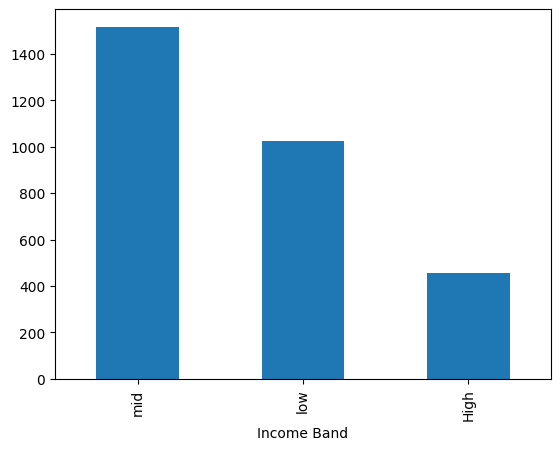

In [27]:
#Adding a new column: Income Band
bins = [0, 100000, 300000, float('inf')]
leable = ['low', 'mid', 'High']

df['Income Band'] = pd.cut(df['Estimated_Income'], bins=bins, labels=leable, right=False)
df['Income Band'].value_counts().plot(kind='bar')

In [34]:
#Examine the Distribution of unique categories in categorical columns
df.columns
categorical_cols = df[["BRId", "GenderId", "IAId", "Amount_of_Credit_Cards", "Nationality", 
                       "Occupation", "Fee_Structure", "Loyalty_Classification", "Properties_Owned", 
                       "Risk_Weighting", "Income Band"]].columns

for col in categorical_cols:
    print(f'Value Counts for {col}')
    display(df[col].value_counts())

Value Counts for BRId


BRId
3    1352
1     660
2     495
4     493
Name: count, dtype: int64

Value Counts for GenderId


GenderId
2    1512
1    1488
Name: count, dtype: int64

Value Counts for IAId


IAId
1     177
3     177
4     177
8     177
2     177
11    176
15    176
14    176
13    176
12    176
10    176
9     176
7      89
6      89
5      89
16     88
17     88
18     88
19     88
20     88
21     88
22     88
Name: count, dtype: int64

... (12 outputs left out)

Value Counts for Risk_Weighting


Risk_Weighting
2    1222
1     836
3     460
4     322
5     160
Name: count, dtype: int64

Value Counts for Income Band


Income Band
mid     1517
low     1027
High     456
Name: count, dtype: int64

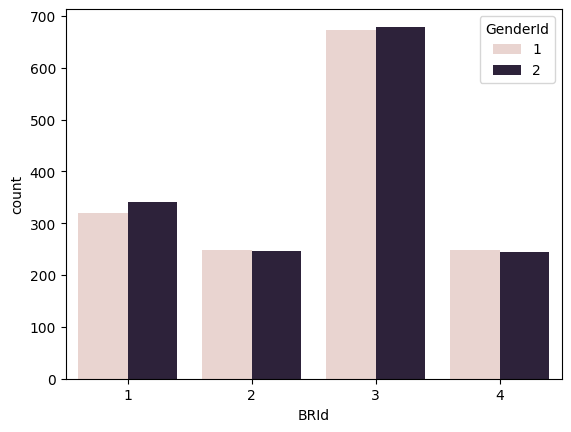

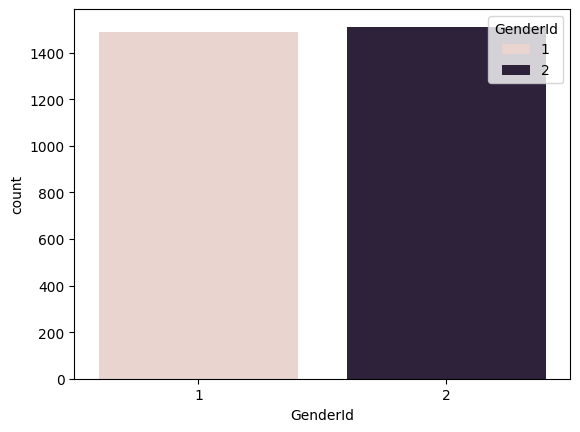

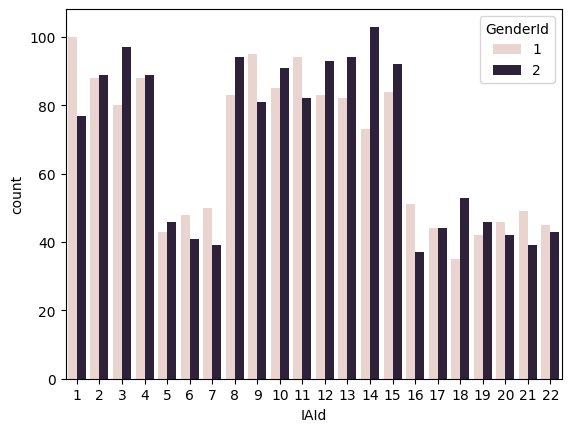

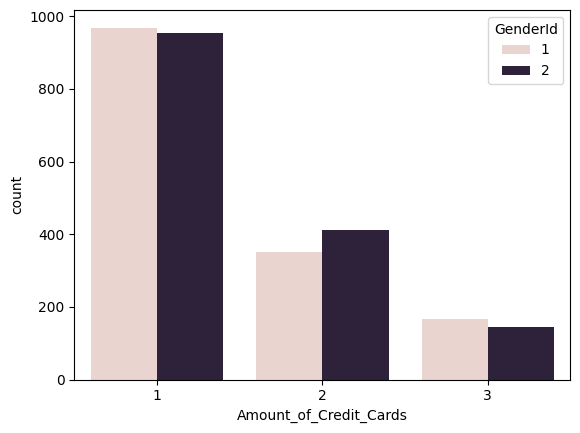

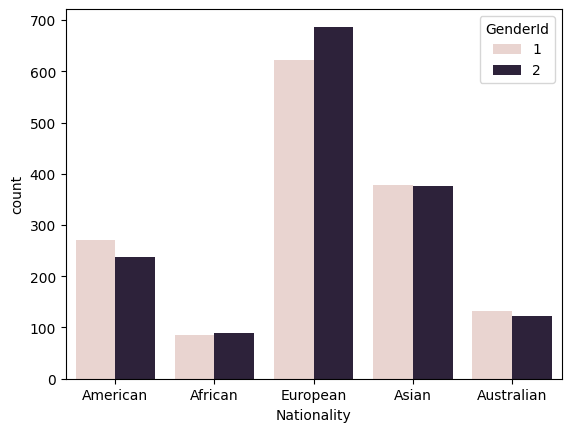

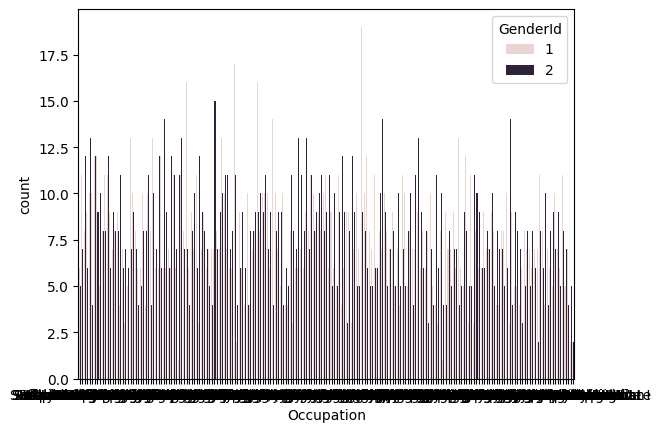

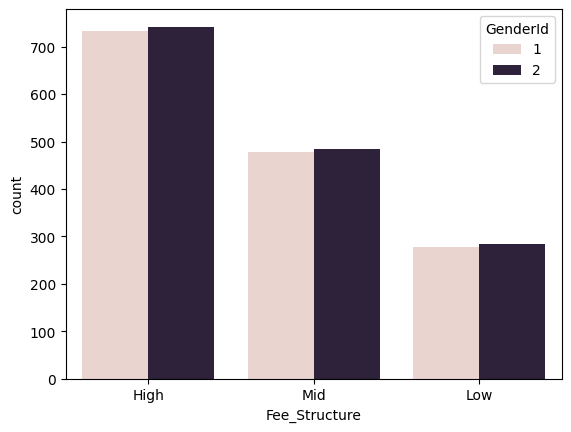

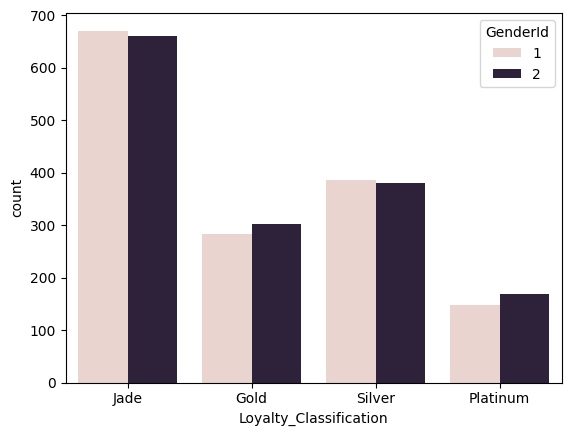

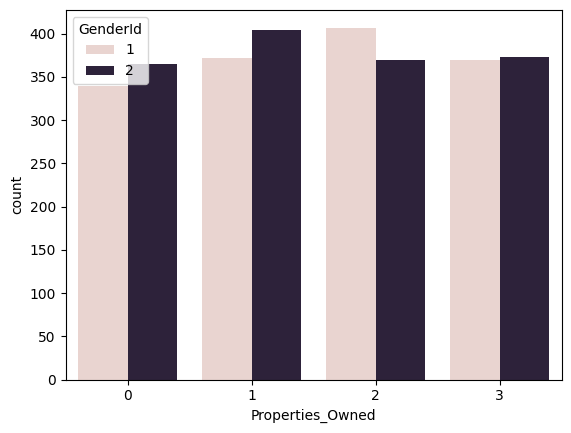

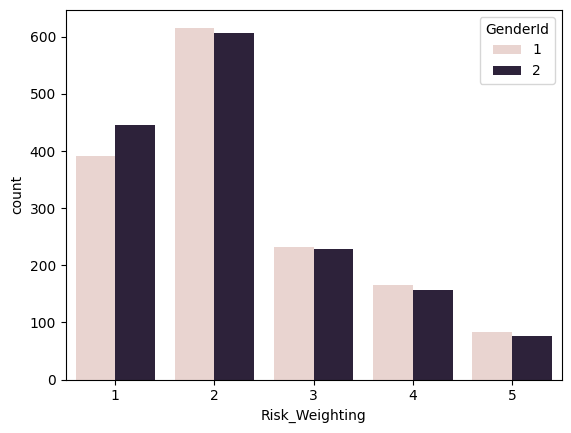

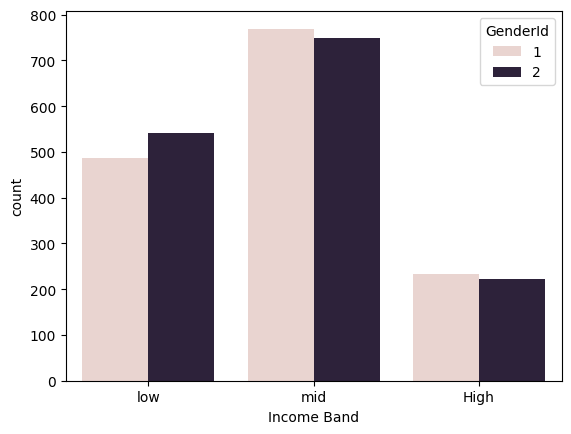

In [ ]:
# Univariate Analysis: one column at a time (reomve hue)
# Bivariate Analysis: Two column at a time
for i, pre in enumerate(categorical_cols):
    plt.figure(i)
    sns.countplot(data=df, x=pre, hue='GenderId')

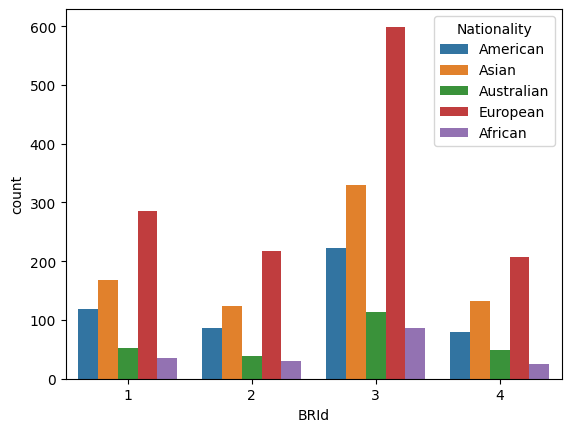

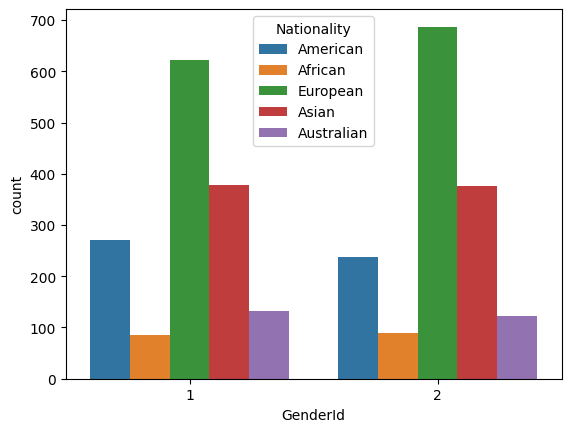

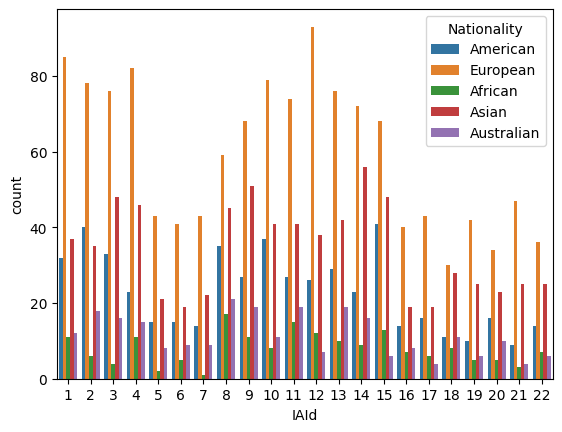

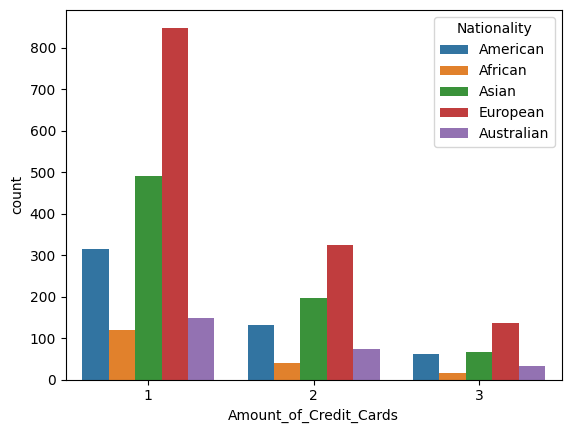

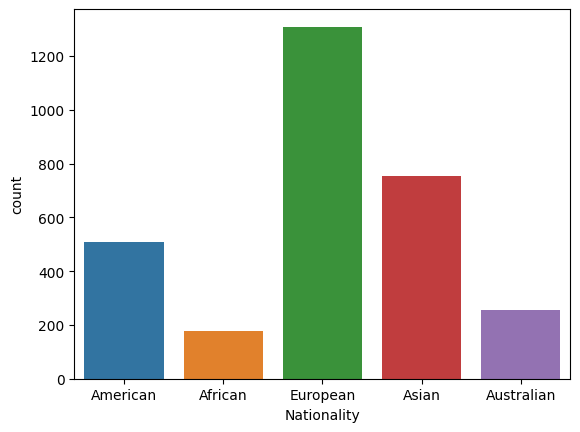

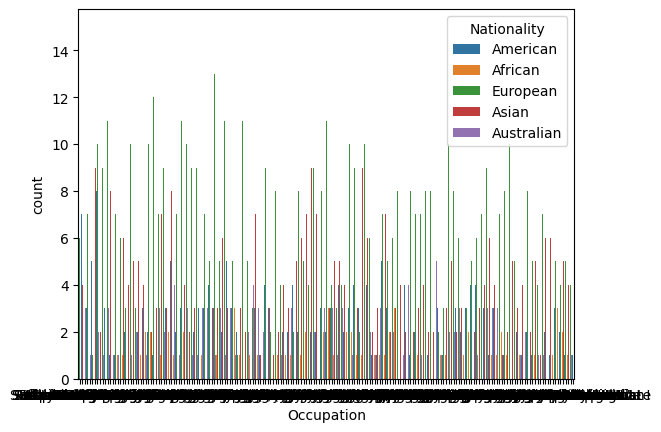

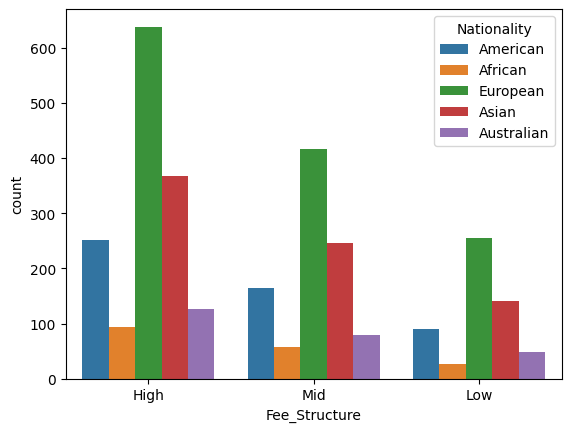

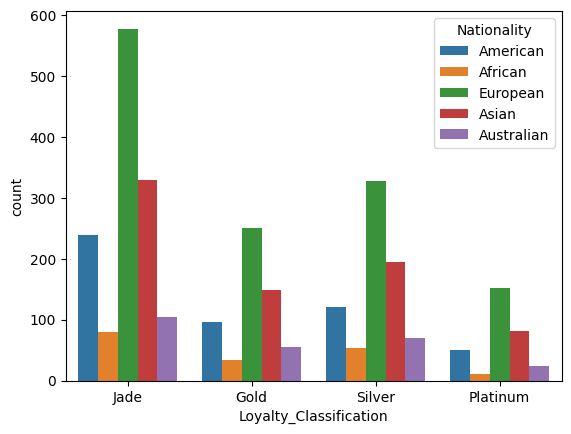

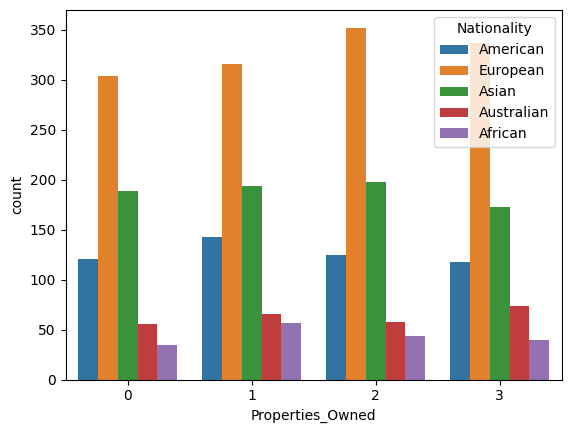

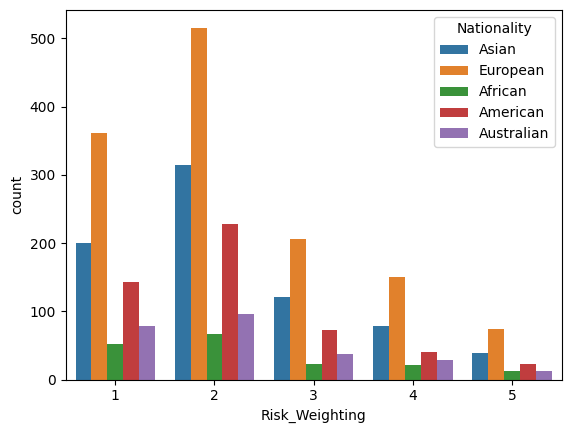

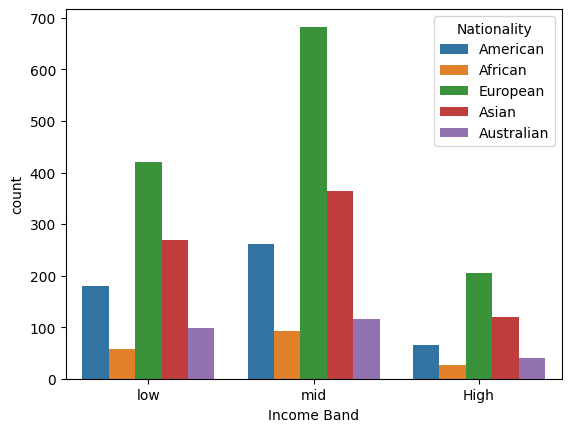

In [37]:
for i, pre in enumerate(categorical_cols):
    plt.figure(i)
    sns.countplot(data=df, x=pre, hue='Nationality')

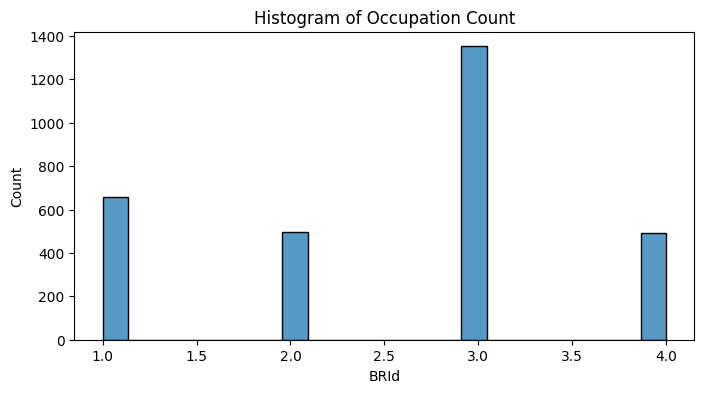

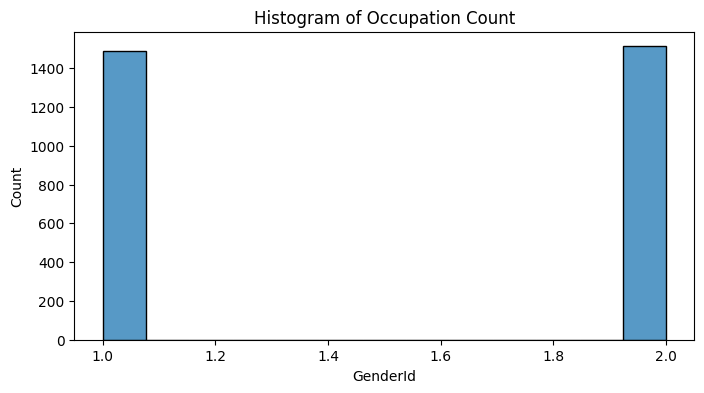

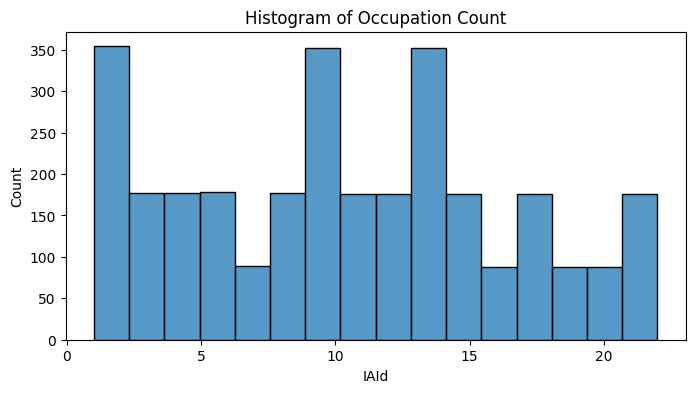

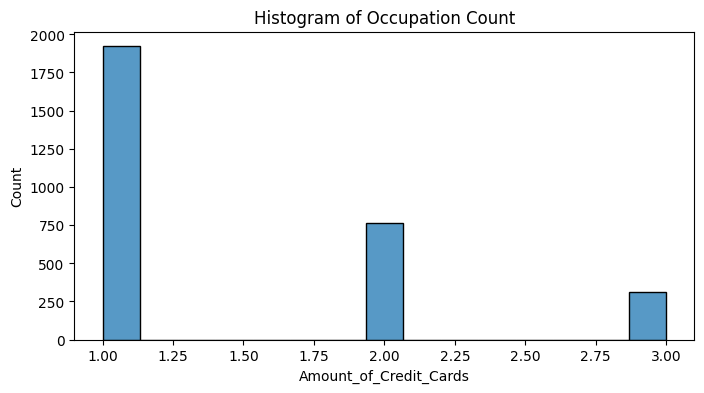

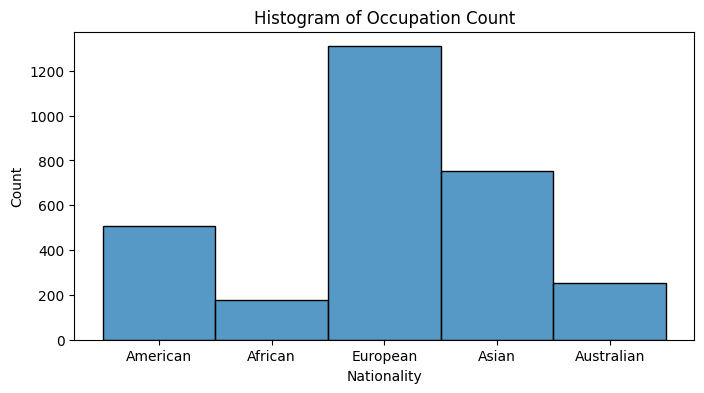

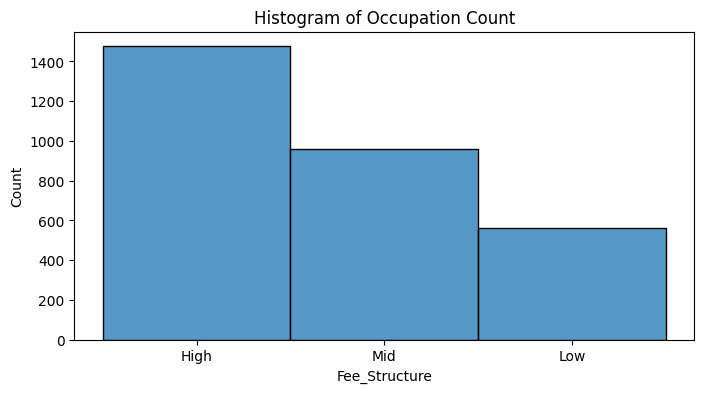

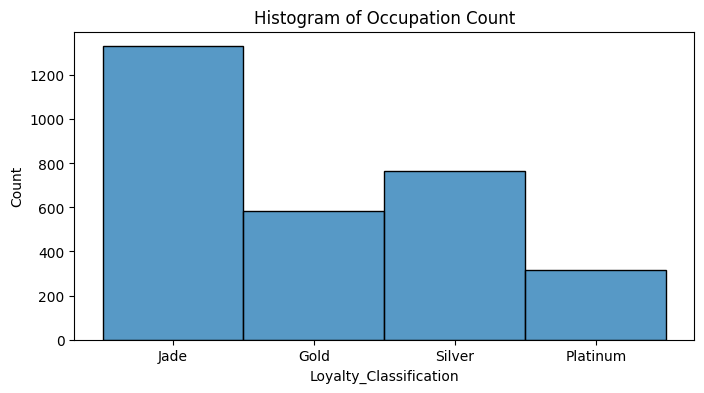

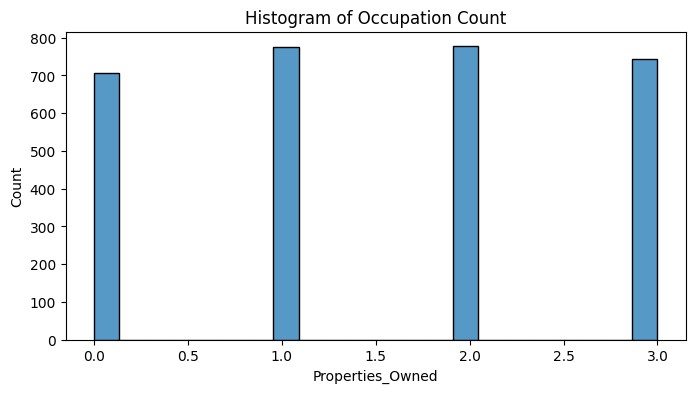

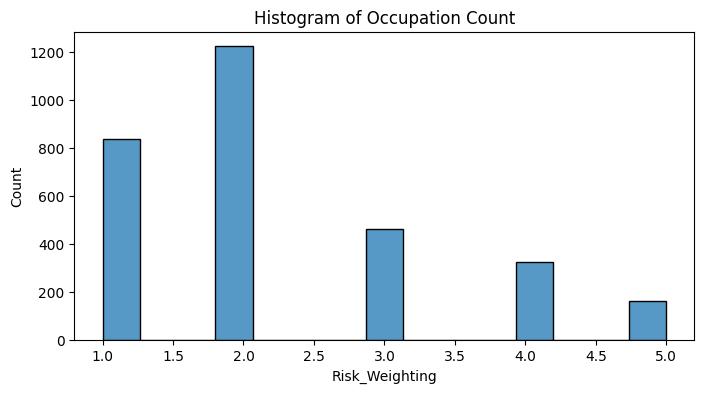

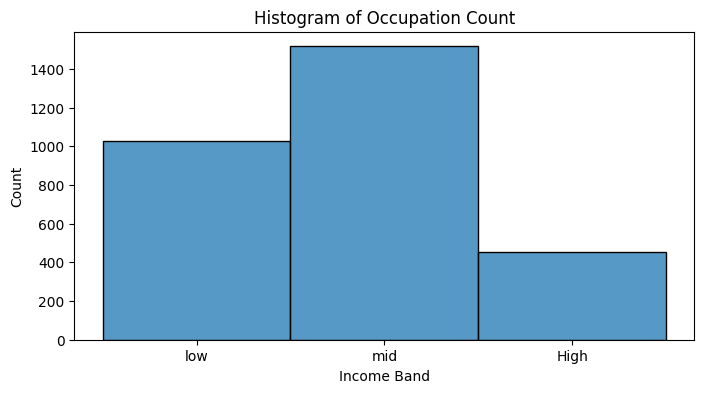

In [38]:
# Histplot of Value count for different Occupation
for col in categorical_cols:
    if col == "Occupation":
        continue
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col])
    plt.title('Histogram of Occupation Count')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

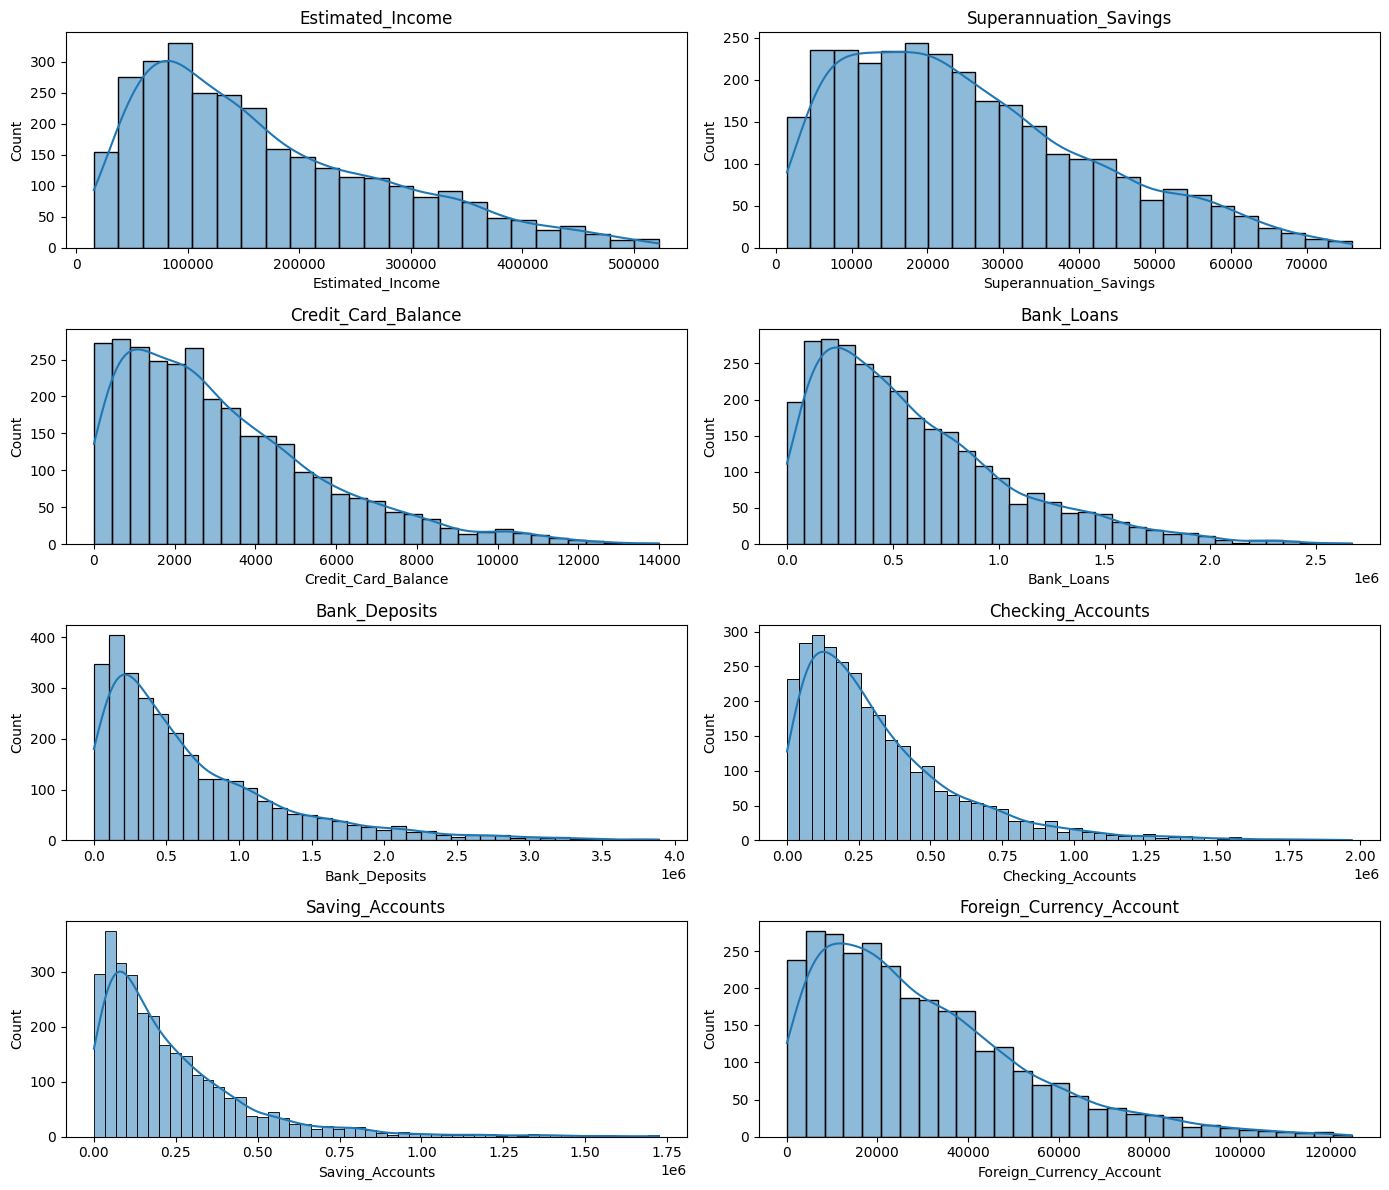

In [49]:
numr_cols = df[['Estimated_Income', 'Superannuation_Savings',
                'Credit_Card_Balance', 'Bank_Loans',
                'Bank_Deposits', 'Checking_Accounts',
                'Saving_Accounts', 'Foreign_Currency_Account']]

plt.figure(figsize=(14, 12))

for i, col in enumerate(numr_cols.columns):
    plt.subplot(4, 2, i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

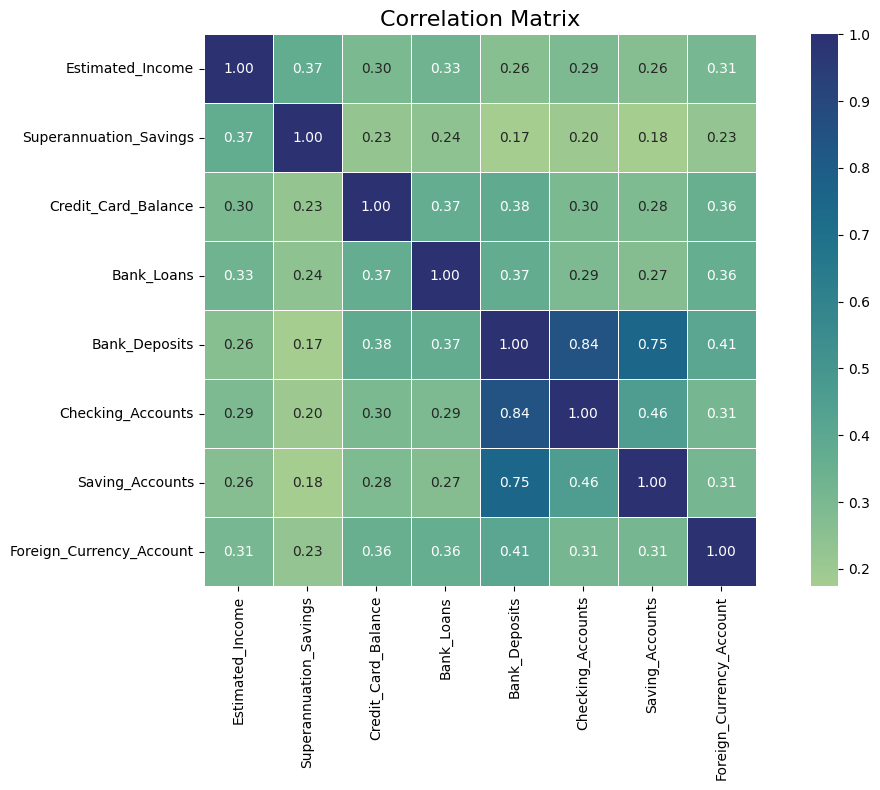

In [53]:
# Correlation matrix
corr_matrix = numr_cols.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='crest',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title('Correlation Matrix', fontsize=16)
plt.tight_layout()
plt.show()